# IPF Performance

The use of iterative proportional fitting (IPF) is quite common on processes
involving doubly-constraining matrices, such as synthetic gravity models and
fractional split models (aggregate destination-choice models).

As this is a commonly used algorithm, we have implemented it in Cython, where
we can take full advantage of multi-core CPUs. Seed matrices can be either 32-bit
or 64-bit floating-point arrays, which has a direct impact on cache use and
consequently on computational performance.

## How it works

The balanced matrix is always the seed matrix with each row and each column multiplied
by a factor, $T_{ij} = a_i \, S_{ij} \, b_j$. Instead of rescaling the whole matrix twice
per iteration, AequilibraE only updates the factors

$$a_i = \frac{P_i}{\sum_j S_{ij} \, b_j} \qquad b_j = \frac{A_j}{\sum_i a_i \, S_{ij}}$$

Each iteration is a single read-only pass over the seed. For every row, the new row factor
comes from the dot product of the row with the column factors and, while the row is still
in cache, its scaled values are added to the column totals that give the new column factors.
The matrix is written only once, at the very end. This produces exactly the same sequence of
iterates as the classic row-then-column algorithm, which reads the matrix four times and writes
it twice in every iteration.

For large matrices, IPF is limited by memory bandwidth rather than by arithmetic, so the amount
of data moved per iteration determines performance. Writing the two sums as BLAS matrix-vector
products (GEMV) is a natural alternative, but it still needs two passes over the matrix per
iteration, even with a multi-threaded BLAS. For the same reason, 32-bit seed matrices are roughly
twice as fast as 64-bit ones. Factors and sums are always accumulated in double precision.

The factors are also available directly through ``ipf_factors``, which never modifies the seed matrix.

## Results

All timings below are for 50 iterations, the best of three runs.

![AequilibraE's IPF runtime, previous vs current implementation](../_images/ipf_runtime_previous_vs_current.png)

Compared with the implementation used until AequilibraE 1.X, the IPF is between 4 and 7 times faster
for matrices with 2,500 zones or more, both on a single thread and on all 24 threads.

![AequilibraE's IPF runtime](../_images/ipf_runtime_aequilibrae_vs_benchmark.png)

On a single thread, AequilibraE is about 6 times faster than a general IPF algorithm written in pure Python, available
[here](https://github.com/joshchea/python-tdm/blob/master/scripts/CalcDistribution.py), for large matrices, and 6.5 to
7 times faster with a 32-bit seed matrix. The previous implementation was barely faster than the pure Python code
on a single thread.

![AequilibraE's IPF runtime 32 vs 64 bits](../_images/ipf_runtime_32vs64bits.png)

With all threads, a 32-bit seed matrix is about twice as fast as a 64-bit one for large matrices, and the results
differ by less than 1e-7 of the largest cell value, the precision of a 32-bit float. AequilibraE is also between
2.2 and 2.5 times faster than the same factor-based algorithm written with NumPy, which relies on a multi-threaded
BLAS for its matrix-vector products but has to read the matrix twice per iteration.

![number of cores used in IPF for 64 bit matrices](../_images/ipf_runtime_vs_num_cores.png)

![number of cores used in IPF for 32 bit matrices](../_images/ipf_runtime_vs_num_cores32bits.png)

Matrices that do not fit in the CPU cache stop scaling once the memory bandwidth is saturated: with 10,000 zones or
more, 24 threads are around 6 times faster than a single thread for 64-bit matrices, and around 10 times faster for
32-bit ones, which move half as much data. Smaller matrices, such as the one with 2,500 zones, keep scaling up to
all 24 threads.

These tests were run on an Intel Core Ultra 9 285K (8 performance and 16 efficient cores, 24 threads) with 192 GB of
RAM, running Windows 11. The code is provided below for reference.

## Reference code

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

from aequilibrae.distribution.cython.ipf_core import ipf_core

In [2]:
# From:
# https://github.com/joshchea/python-tdm/blob/master/scripts/CalcDistribution.py

def CalcFratar(ProdA, AttrA, Trips1, maxIter=10):
    '''Calculates fratar trip distribution
       ProdA = Production target as array
       AttrA = Attraction target as array
       Trips1 = Seed trip table for fratar
       maxIter (optional) = maximum iterations, default is 10
       Returns fratared trip table
    '''
    sumP = ProdA.sum()
    sumA = AttrA.sum()
    if sumP != sumA:
        AttrA = AttrA*(sumP/sumA)
    # Run 2D balancing --->
    for balIter in range(0, maxIter):
        ComputedProductions = Trips1.sum(1)
        ComputedProductions[ComputedProductions == 0] = 1
        OrigFac = (ProdA/ComputedProductions)
        Trips1 = Trips1*OrigFac[:, np.newaxis]

        ComputedAttractions = Trips1.sum(0)
        ComputedAttractions[ComputedAttractions == 0] = 1
        DestFac = (AttrA/ComputedAttractions)
        Trips1 = Trips1*DestFac
    return Trips1

In [3]:
def numpy_gemv(productions, attractions, trips, iterations):
    # The same factor-based algorithm, with two BLAS matrix-vector products per iteration.
    # NumPy's BLAS is multi-threaded and picks its own number of threads
    columns = np.ones(trips.shape[1], dtype=trips.dtype)
    productions, attractions = productions.astype(trips.dtype), attractions.astype(trips.dtype)
    for _ in range(iterations):
        rows = productions / (trips @ columns)
        columns = attractions / (rows @ trips)
    trips *= rows[:, np.newaxis]
    trips *= columns[np.newaxis, :]
    return trips

In [4]:
def problem(zones, rng):
    seed = rng.random((zones, zones))
    productions = rng.random(zones) * 1000
    attractions = rng.random(zones) * 1000
    attractions *= productions.sum() / attractions.sum()
    return seed, productions, attractions


def best_time(function, seed, repetitions):
    # Every run gets a fresh copy of the seed, made outside the timed region
    times = []
    for _ in range(repetitions):
        trips = seed.copy()
        t = perf_counter()
        function(trips)
        times.append(perf_counter() - t)
    return min(times)


def aequilibrae(productions, attractions, iterations, cores):
    # We use a nonsensical negative tolerance to force it to run all iterations
    # and set warning for non-convergence to false, as we know it won't converge
    def run(trips):
        ipf_core(trips, productions, attractions, max_iterations=iterations, tolerance=-5, cores=cores, warn=False)
    return run

In [5]:
mat_sizes = [1000, 2500, 5000, 10000, 15000]
iterations = 50
repetitions = 3
all_threads = 24
rng = np.random.default_rng(42)
problems = {zones: problem(zones, rng) for zones in mat_sizes}

### Single thread

In [6]:
bench_data = []
for zones in tqdm(mat_sizes):
    seed, target_prod, target_atra = problems[zones]
    python = best_time(lambda trips: CalcFratar(target_prod, target_atra, trips, maxIter=iterations), seed, repetitions)
    aeq = best_time(aequilibrae(target_prod, target_atra, iterations, 1), seed, repetitions)
    aeq32 = best_time(aequilibrae(target_prod, target_atra, iterations, 1), seed.astype(np.float32), repetitions)
    bench_data.append([zones, python, aeq, aeq32])

  0%|          | 0/5 [00:00<?, ?it/s]

 20%|██        | 1/5 [00:00<00:03,  1.02it/s]

 40%|████      | 2/5 [00:07<00:13,  4.34s/it]

 60%|██████    | 3/5 [00:34<00:28, 14.49s/it]

 80%|████████  | 4/5 [02:16<00:49, 49.23s/it]

100%|██████████| 5/5 [06:14<00:00, 117.16s/it]

100%|██████████| 5/5 [06:14<00:00, 74.87s/it] 

,PythonCode,AequilibraE,AequilibraE-32bits
Zones in the model,,,
1000,0.256157,0.028836,0.033302
2500,1.588531,0.302002,0.262885
5000,6.460616,1.089112,1.049418
10000,25.190976,4.266291,3.870072
15000,58.446468,10.073509,8.417054


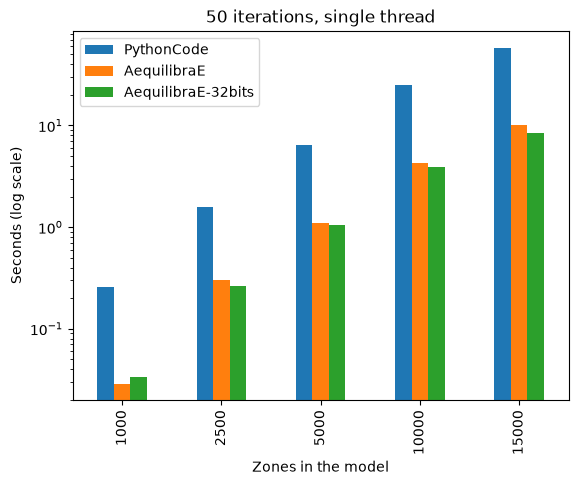

In [7]:
bench_df = pd.DataFrame(bench_data, columns=["Zones in the model", "PythonCode", "AequilibraE", "AequilibraE-32bits"])
bench_df = bench_df.set_index("Zones in the model")
ax = bench_df.plot.bar(logy=True, ylabel="Seconds (log scale)", title=f"{iterations} iterations, single thread")
ax.figure.savefig("../_images/ipf_runtime_aequilibrae_vs_benchmark.png", dpi=100, bbox_inches="tight")
bench_df

### All threads

In [8]:
bench_data_parallel = []
for zones in tqdm(mat_sizes):
    seed, target_prod, target_atra = problems[zones]
    aeq = best_time(aequilibrae(target_prod, target_atra, iterations, all_threads), seed, repetitions)
    aeq32 = best_time(aequilibrae(target_prod, target_atra, iterations, all_threads), seed.astype(np.float32), repetitions)
    blas = best_time(lambda trips: numpy_gemv(target_prod, target_atra, trips, iterations), seed, repetitions)
    blas32 = best_time(lambda trips: numpy_gemv(target_prod, target_atra, trips, iterations), seed.astype(np.float32), repetitions)

    # How far the 32-bit result is from the 64-bit one
    mat64, mat32 = seed.copy(), seed.astype(np.float32)
    ipf_core(mat64, target_prod, target_atra, max_iterations=iterations, tolerance=-5, cores=all_threads, warn=False)
    ipf_core(mat32, target_prod, target_atra, max_iterations=iterations, tolerance=-5, cores=all_threads, warn=False)
    rel_diff = np.abs(mat32 - mat64).max() / mat64.max()

    bench_data_parallel.append([zones, aeq, aeq32, blas, blas32, rel_diff])

  0%|          | 0/5 [00:00<?, ?it/s]

 20%|██        | 1/5 [00:00<00:00,  7.11it/s]

 40%|████      | 2/5 [00:00<00:01,  2.33it/s]

 60%|██████    | 3/5 [00:04<00:03,  1.92s/it]

 80%|████████  | 4/5 [00:20<00:07,  7.38s/it]

100%|██████████| 5/5 [00:54<00:00, 17.18s/it]

100%|██████████| 5/5 [00:54<00:00, 10.96s/it]

,AequilibraE,AequilibraE-32bits,NumPy-BLAS,NumPy-BLAS-32bits,max rel. diff 32 vs 64 bits
Zones in the model,,,,,
1000,0.002849,0.002788,0.012953,0.011279,5.804541e-08
2500,0.020774,0.013575,0.065954,0.025114,6.476174e-08
5000,0.176206,0.085208,0.407466,0.193082,6.579868e-08
10000,0.786698,0.375041,1.741401,0.940168,6.555376e-08
15000,1.670460,0.832983,3.790379,1.929073,8.352734e-08


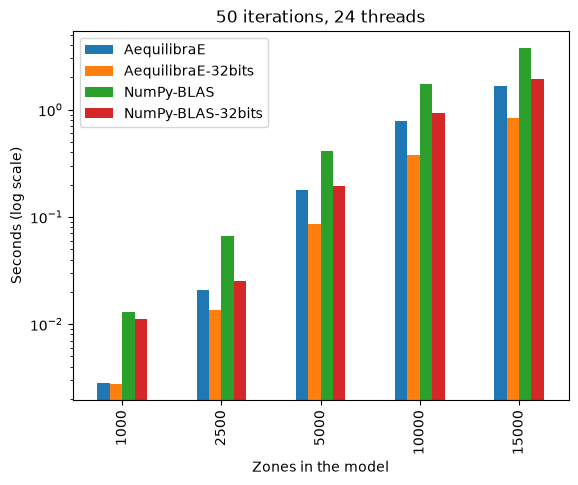

In [9]:
columns = ["Zones in the model", "AequilibraE", "AequilibraE-32bits", "NumPy-BLAS", "NumPy-BLAS-32bits", "max rel. diff 32 vs 64 bits"]
bench_df_parallel = pd.DataFrame(bench_data_parallel, columns=columns).set_index("Zones in the model")
ax = bench_df_parallel[columns[1:5]].plot.bar(logy=True, ylabel="Seconds (log scale)", title=f"{iterations} iterations, {all_threads} threads")
ax.figure.savefig("../_images/ipf_runtime_32vs64bits.png", dpi=100, bbox_inches="tight")
bench_df_parallel

### Scaling with the number of threads

In [10]:
cores_to_use = [1, 2, 4, 8, 16, 24]
aeq_data = []
for zones in tqdm(mat_sizes[1:]):
    seed, target_prod, target_atra = problems[zones]
    for dtype in [np.float64, np.float32]:
        typed_seed = seed.astype(dtype)
        for cores in cores_to_use:
            t = best_time(aequilibrae(target_prod, target_atra, iterations, cores), typed_seed, 1)
            aeq_data.append([zones, np.dtype(dtype).name, cores, t])
aeq_df = pd.DataFrame(aeq_data, columns=["zones", "dtype", "cores", "time"])

  0%|          | 0/4 [00:00<?, ?it/s]

 25%|██▌       | 1/4 [00:01<00:03,  1.31s/it]

 50%|█████     | 2/4 [00:06<00:07,  3.76s/it]

 75%|███████▌  | 3/4 [00:28<00:12, 12.16s/it]

100%|██████████| 4/4 [01:18<00:00, 27.09s/it]

100%|██████████| 4/4 [01:18<00:00, 19.73s/it]

cores,1,2,4,8,16,24
zones,,,,,,
2500,1.0,1.891489,3.603211,6.997106,11.177790,13.259920
5000,1.0,1.682420,3.182825,5.210766,6.861622,6.845046
10000,1.0,1.751420,3.105562,4.403694,4.895484,5.659009
15000,1.0,1.761062,3.138971,4.497751,5.964850,6.428735


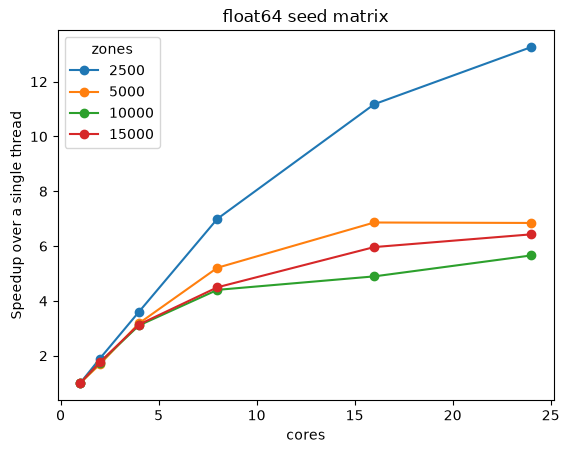

In [11]:
def speedup(dtype, file_name):
    df = aeq_df[aeq_df.dtype == dtype].pivot_table(index="zones", columns="cores", values="time")
    df = 1 / df.div(df[1], axis=0)
    ax = df.transpose().plot(marker="o", ylabel="Speedup over a single thread", title=f"{dtype} seed matrix")
    ax.figure.savefig(file_name, dpi=100, bbox_inches="tight")
    return df

speedup("float64", "../_images/ipf_runtime_vs_num_cores.png")

cores,1,2,4,8,16,24
zones,,,,,,
2500,1.0,2.187145,4.564718,7.407718,13.465763,15.074259
5000,1.0,2.147890,4.030197,7.311317,12.054202,14.652930
10000,1.0,1.870480,3.677779,6.728126,10.021640,10.860277
15000,1.0,1.879772,3.564164,6.466850,9.430977,10.122075


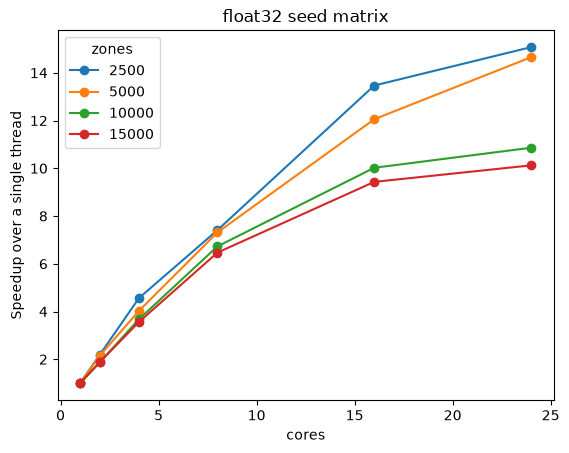

In [12]:
speedup("float32", "../_images/ipf_runtime_vs_num_cores32bits.png")

### Comparison with the previous implementation

Until AequilibraE 2.0, the IPF rescaled the whole matrix in place twice per iteration. The timings
below were measured for that implementation on the same machine, with the same problem sizes,
iteration count and number of repetitions.

In [13]:
# zones, seed type, threads, seconds
previous = pd.DataFrame([
    (1000, "float64", 1, 0.1972),
    (1000, "float64", 24, 0.0413),
    (1000, "float32", 1, 0.1719),
    (1000, "float32", 24, 0.0272),
    (2500, "float64", 1, 1.5693),
    (2500, "float64", 24, 0.1173),
    (2500, "float32", 1, 1.2473),
    (2500, "float32", 24, 0.0889),
    (5000, "float64", 1, 6.1182),
    (5000, "float64", 24, 1.1338),
    (5000, "float32", 1, 4.9165),
    (5000, "float32", 24, 0.5683),
    (10000, "float64", 1, 23.5490),
    (10000, "float64", 24, 4.4707),
    (10000, "float32", 1, 19.3165),
    (10000, "float32", 24, 2.3520),
    (15000, "float64", 1, 44.4259),
    (15000, "float64", 24, 10.4521),
    (15000, "float32", 1, 43.5095),
    (15000, "float32", 24, 5.8998)
], columns=["zones", "dtype", "cores", "previous"])

current = pd.concat([
    bench_df[["AequilibraE", "AequilibraE-32bits"]].assign(cores=1),
    bench_df_parallel[["AequilibraE", "AequilibraE-32bits"]].assign(cores=all_threads),
]).rename(columns={"AequilibraE": "float64", "AequilibraE-32bits": "float32"})
current = current.reset_index().melt(id_vars=["Zones in the model", "cores"], var_name="dtype", value_name="current")
current = current.rename(columns={"Zones in the model": "zones"})

comparison = previous.merge(current, on=["zones", "dtype", "cores"])
comparison["speedup"] = comparison.previous / comparison.current
comparison.pivot_table(index="zones", columns=["cores", "dtype"], values="speedup").round(1)

cores      1               24        
dtype float32 float64 float32 float64
zones                                
1000      5.2     6.8     9.8    14.5
2500      4.7     5.2     6.5     5.6
5000      4.7     5.6     6.7     6.4
10000     5.0     5.5     6.3     5.7
15000     5.2     4.4     7.1     6.3

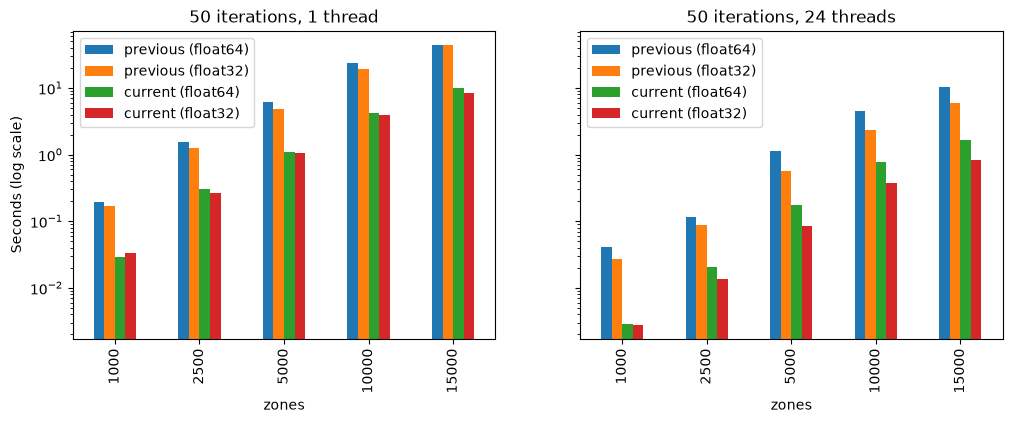

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, cores in zip(axes, [1, all_threads]):
    df = comparison[comparison.cores == cores].pivot_table(index="zones", columns="dtype", values=["previous", "current"])
    df.columns = [f"{when} ({dtype})" for when, dtype in df.columns]
    df[sorted(df.columns, reverse=True)].plot.bar(ax=ax, logy=True, ylabel="Seconds (log scale)",
                                                  title=f"{iterations} iterations, {cores} thread{'s' if cores > 1 else ''}")
fig.savefig("../_images/ipf_runtime_previous_vs_current.png", dpi=100, bbox_inches="tight")